# Chapter 5: Basic Inequalities and the Law of Large Numbers

The computational applications of this chapter of *Theory of Statistics*. The code is generated automatically from the book's `code/ch05/` files; see the book for the explanations and proofs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/izupress/statistical-theory/blob/main/notebooks/ch_05.ipynb)

$$
\newcommand{\R}{\mathbb{R}}\newcommand{\N}{\mathbb{N}}\newcommand{\E}{\mathbb{E}}
\newcommand{\P}{\mathbb{P}}\newcommand{\F}{\mathcal{F}}\newcommand{\I}{\mathbb{I}}
\newcommand{\Var}{\operatorname{Var}}\newcommand{\Cov}{\operatorname{Cov}}
\newcommand{\Corr}{\operatorname{Corr}}\newcommand{\MSE}{\operatorname{MSE}}
\newcommand{\Bias}{\operatorname{Bias}}\newcommand{\Normal}{\mathcal{N}}
\newcommand{\iid}{\overset{\text{i.i.d.}}{\sim}}\newcommand{\pto}{\xrightarrow{P}}
\newcommand{\dto}{\xrightarrow{d}}\newcommand{\X}{\mathbf{X}}\newcommand{\x}{\mathbf{x}}
$$

In [1]:
# Setup: numpy, scipy and matplotlib are preinstalled on Colab. Locally:
#   pip install -r code/requirements.txt
# Figure files (PDF) saved by the code are written to the _figures/ folder; the figures are
# also shown inside the notebook.
import os
os.makedirs("_figures", exist_ok=True)
os.chdir("_figures")
%matplotlib inline

## An Empirical Check of Chebyshev's Bound

For $X\sim\text{Gamma}(2,\tfrac12)$ (shape $2$, rate $\tfrac12$), $\mu=\alpha/\beta=4$ and $\sigma^2=\alpha/\beta^2=8$.

*Source file:* `code/ch05/c05_1_chebyshev_empirical_check.py`

In [2]:
import numpy as np

rng = np.random.default_rng(42)
samples = rng.gamma(shape=2.0, scale=2.0, size=500_000)   # rate 1/2 <=> scale 2
sigma = np.sqrt(8.0)
for k in [1.5, 2.0, 3.0, 4.0]:
    print(f"k = {k:.1f} | Empirical: {np.mean(np.abs(samples - 4.0) >= k * sigma):.4f} <= Chebyshev: {1.0/(k**2):.4f}")

k = 1.5 | Empirical: 0.0830 <= Chebyshev: 0.4444
k = 2.0 | Empirical: 0.0464 <= Chebyshev: 0.2500
k = 3.0 | Empirical: 0.0140 <= Chebyshev: 0.1111
k = 4.0 | Empirical: 0.0042 <= Chebyshev: 0.0625


## How Well Do the Sample-Size Rules Really Perform?

*Source file:* `code/ch05/c05_2_sample_size_rules.py`

In [3]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)
eps, delta, R = 0.05, 0.05, 200_000
rules = {"Chebyshev": int(np.ceil(1/(4*eps**2*delta))),
            "Hoeffding": int(np.ceil(np.log(2/delta)/(2*eps**2))),
            "CLT":       int(np.ceil((stats.norm.ppf(1-delta/2)/(2*eps))**2))}
for p in [0.5, 0.2]:
    for name, n in rules.items():
        p_hat = rng.binomial(n, p, size=R) / n
        err = np.mean(np.abs(p_hat - p) >= eps)
        print(f"p={p} | {name:9s} n={n:4d} | P(|p_hat-p|>=0.05) = {err:.4f} (target <= {delta})")

p=0.5 | Chebyshev n=2000 | P(|p_hat-p|>=0.05) = 0.0000 (target <= 0.05)
p=0.5 | Hoeffding n= 738 | P(|p_hat-p|>=0.05) = 0.0072 (target <= 0.05)
p=0.5 | CLT       n= 385 | P(|p_hat-p|>=0.05) = 0.0528 (target <= 0.05)
p=0.2 | Chebyshev n=2000 | P(|p_hat-p|>=0.05) = 0.0000 (target <= 0.05)
p=0.2 | Hoeffding n= 738 | P(|p_hat-p|>=0.05) = 0.0007 (target <= 0.05)
p=0.2 | CLT       n= 385 | P(|p_hat-p|>=0.05) = 0.0130 (target <= 0.05)


## The Law of Large Numbers and the Cauchy Counterexample

*Source file:* `code/ch05/c05_3_lln_and_cauchy.py`

n=    1 | interquartile width of the Cauchy mean: 1.948 (theory 2.000)
n=   10 | interquartile width of the Cauchy mean: 2.011 (theory 2.000)


n= 1000 | interquartile width of the Cauchy mean: 2.007 (theory 2.000)


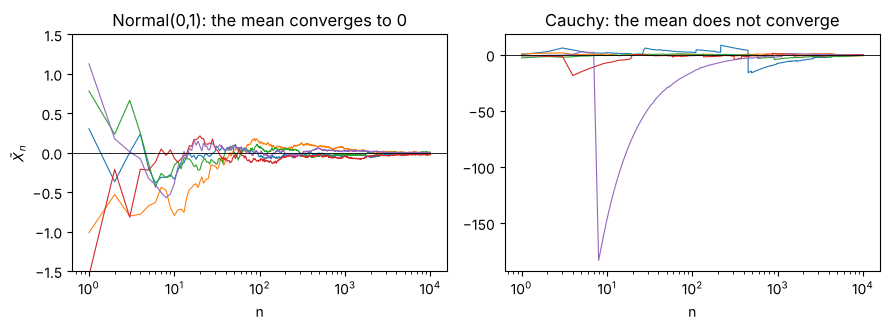

In [4]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n = np.arange(1, 10_001)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4), sharex=True)
for r in range(5):
    ax[0].plot(n, np.cumsum(rng.normal(size=n.size)) / n, lw=0.8)
    ax[1].plot(n, np.cumsum(rng.standard_cauchy(size=n.size)) / n, lw=0.8)
ax[0].set_title("Normal(0,1): the mean converges to 0"); ax[1].set_title("Cauchy: the mean does not converge")
for a in ax:
    a.set_xscale("log"); a.axhline(0, color="k", lw=0.6); a.set_xlabel("n")
ax[0].set_ylim(-1.5, 1.5); ax[0].set_ylabel(r"$\bar X_n$")
fig.tight_layout(); fig.savefig("lln_cauchy.pdf")

# The distribution of the Cauchy sample mean does not depend on n:
for m in [1, 10, 1000]:
    xbar = rng.standard_cauchy(size=(20_000, m)).mean(axis=1)
    q = np.percentile(xbar, [25, 75])
    print(f"n={m:5d} | interquartile width of the Cauchy mean: {q[1]-q[0]:.3f} (theory 2.000)")